# 05 — VECM, señales, sizing y búsqueda de umbrales

**Dueño:** Gonzalo Cano (GC) · **Revisor:** Juan Manuel Espinosa (JME) · **Guía:** `docs/instrucciones/05_vecm_senales.md`

**Objetivo.** Convertir el z-score prior del filtro 2 en posiciones por activo (grupo: tercia GLD-GDX-B, iteración 2):

1. **VECM en train:** qué activos corrigen cuando el spread se abre (α) y a qué velocidad (βᵀα).
2. **Regla de bandas** sobre z_t con θ = (z_entrada, z_salida, z_stop, h_max), la PFA de la sesión 11.
3. **Sizing:** 80 % del capital repartido según |β̂_t| (`strategy/sizing.py`, escrito por JME para el motor).
4. **Grid search de θ solo en train**, con el Sharpe neto de costos del motor de la parte 06.

> Este notebook solo **muestra**: la lógica vive en `strategy/` y es la misma que ejecuta `python main.py`. La rejilla,
> el objetivo y la regla se registraron en `docs/decisiones.md` **antes** de ver resultados.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from kalman.weights_filter import ect_comparison
from main import ARTIFACTS, FIGURES
from strategy.optimization import MIN_TRADES, compare_static_dynamic, evaluate_by_split
from strategy.signals import SignalRule, generate_signals
from strategy.sizing import POSITION_FRACTION, target_shares

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

prices = pd.read_parquet(ARTIFACTS / "prices.parquet")
split = prices.pop("split")
kf1 = pd.read_parquet(ARTIFACTS / "kf1_weights.parquet")
signals = pd.read_parquet(ARTIFACTS / "signals.parquet")
grid = pd.read_csv(ARTIFACTS / "grid_search.csv")
johansen = json.loads((ARTIFACTS / "johansen_summary.json").read_text())
vecm = json.loads((ARTIFACTS / "vecm_summary.json").read_text())
strategy = json.loads((ARTIFACTS / "params.json").read_text())["strategy"]
kf2_params = json.loads((ARTIFACTS / "params.json").read_text())["kf2"]
tickers = johansen["tickers"]
rule = SignalRule(strategy["z_entry"], strategy["z_exit"], strategy["z_stop"], strategy["max_holding"])
print("grupo:", "-".join(tickers), "| θ congelado:", rule)

grupo: GLD-GDX-B | θ congelado: SignalRule(z_entry=1.0, z_exit=0.0, z_stop=2.5, max_holding=87)


## 1. VECM en entrenamiento

$$\Delta \ln P_t = \alpha\,(\tilde\beta^\top \ln P_{t-1} - c) + \Gamma_1\,\Delta \ln P_{t-1} + \varepsilon_t$$

Se estima con `statsmodels` con `deterministic="co"`, que es el mismo caso que `det_order = 0` de Johansen, con r = 1 y
k_ar_diff = 1 como en la parte 02. Así el β que estima el VECM **es exactamente** el β̃ de Johansen (se verifica con
tolerancia 1e-6), y α queda en la misma escala.

In [2]:
table = pd.DataFrame({"β̃ (Johansen)": vecm["beta_normalized"], "α": vecm["alpha"], "error est.": vecm["alpha_stderr"],
                      "t": vecm["alpha_tstat"]})
display(table)
print(f"βᵀα = {vecm['beta_alpha']:.4f}  →  corrige hacia el equilibrio (−2 < βᵀα < 0): {vecm['error_correction']}")
print(f"vida media implícita del VECM: −ln 2 / ln(1 + βᵀα) = {vecm['half_life_days']:.1f} días")
print(f"α significativo al 5 %: {vecm['alpha_significant_5pct']}")

,β̃ (Johansen),α,error est.,t
GLD,-0.8266,-0.003369,0.003549,-0.9492
GDX,1,-0.0386,0.009435,-4.091
B,-0.4481,-0.03389,0.009878,-3.431


βᵀα = -0.0206  →  corrige hacia el equilibrio (−2 < βᵀα < 0): True
vida media implícita del VECM: −ln 2 / ln(1 + βᵀα) = 33.3 días
α significativo al 5 %: ['GDX', 'B']


**Qué dicen los α.** Con ECT = ln GDX − 0.827 ln GLD − 0.448 ln B − c, un ECT positivo significa que el ETF de
mineras está caro frente al oro y a Barrick. Los α significativos son los de **GDX (−0.039, t ≈ −4.1)** y **B (−0.034,
t ≈ −3.4)**; el del oro no es distinguible de cero. Cuando el spread se abre, **GDX es el que corrige** (baja), y Barrick,
que es uno de sus mayores componentes, se mueve con él; el oro casi no participa en el ajuste.

Ojo con B: su α es significativo, pero **no corrige**. La contribución de cada activo a βᵀα es β̃_i·α_i:
GDX −0.039 (cierra el spread), B +0.015 y GLD +0.003 (lo abren). Como β̃_B < 0, que B baje cuando el spread está
arriba lo empuja más arriba: Barrick se mueve con el ETF que la contiene, no contra él. Toda la corrección la hace GDX.

**Tres estimaciones de la velocidad de reversión, todas en train:**

| Fuente | Vida media |
|---|---|
| OU sobre el spread de Johansen (parte 02) | 29.1 días |
| VECM, βᵀα = −0.021 | 33.3 días |
| φ del filtro 2 sobre el ECT dinámico (parte 04) | 22.1 días |

Coinciden en el orden de magnitud: el spread cierra la mitad de una desviación en 4 a 7 semanas. El holding máximo usa
la de la parte 02, que es la misma que calibra los filtros 1 y 2.

**¿Qué aporta el VECM si ya tenemos Kalman?** Confirma que la relación de Johansen es de corrección de error y no solo
estacionaria por casualidad, dice qué activo hace el ajuste y da una vida media independiente del filtro.

*Iteración 1 (GLD-GDX-AEM-FNV), como referencia: el único α significativo era el de GLD (−0.015) y βᵀα = −0.026.*

## 2. Qué serie alimenta al filtro 2: ECT dinámico contra estático

El profesor aclaró que el "residual del VECM" es el **ECT que el filtro 1 produce día a día** (β̂_{t|t−1}ᵀ ln P_t − ĉ),
no ε_t. La versión estática usa el β̃ y la c de Johansen congelados en train. Fuera de muestra el estático se desplaza
(media −0.06 en prueba y −0.10 en validación) y deja de ser estacionario en prueba; el dinámico se queda centrado y
estacionario.

mean     std  adf_stat  adf_pvalue  half_life
ect     split                                                        
static  train       -0.01014 0.05193     -4.48   0.0002137      22.79
        test        -0.06263 0.05002     -2.03      0.2734      47.17
        validation   -0.1008  0.0407    -3.196     0.02021      25.69
dynamic train      -0.009915 0.05078    -4.448   0.0002438      22.15
        test        -0.01873 0.03973    -2.826     0.05471      27.39
        validation  0.002924 0.04058    -3.404     0.01084      23.85

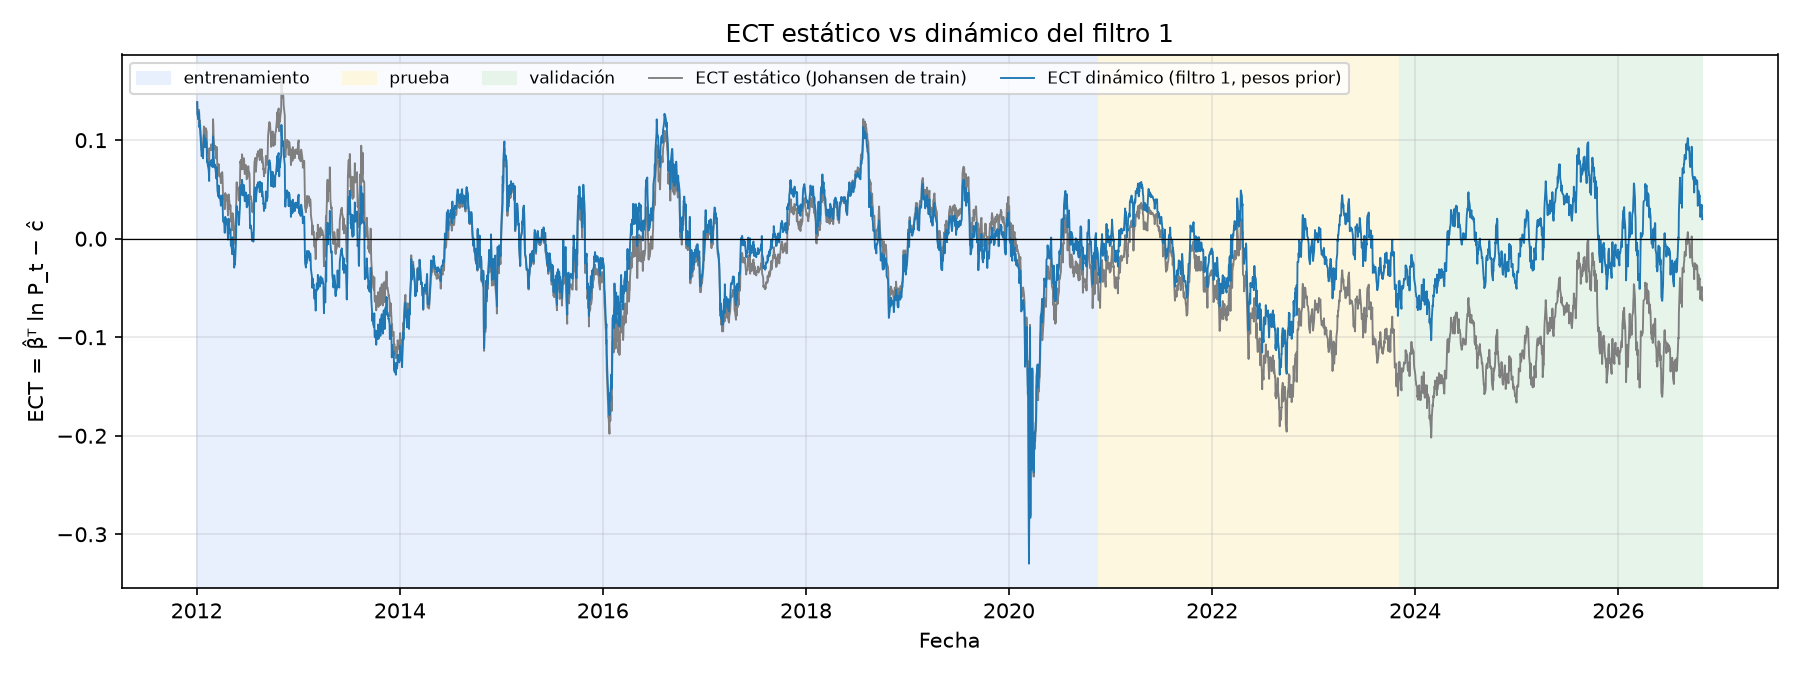

In [3]:
display(ect_comparison(kf1).set_index(["ect", "split"]))
display(Image(FIGURES / "ect_estatico_vs_dinamico.png"))

## 3. La regla de señales

Decidida al cierre de t con z_t prior; el motor la ejecuta al cierre de t + 1.

| Estado | Condición | Decisión |
|---|---|---|
| plano | −z_stop < z_t < −z_entrada | **largo** el spread (comprar β̃ > 0: GDX; vender GLD y B) |
| plano | z_entrada < z_t < z_stop | **corto** el spread |
| con posición | \|z_t\| ≥ z_stop | cerrar por **stop** |
| con posición | h_t ≥ h_max | cerrar por **holding** |
| largo (corto) | z_t ≥ −z_salida (z_t ≤ z_salida) | cerrar por **salida** |

Las cuatro decisiones que la clase deja abiertas (`docs/decisiones.md`):

- **Prioridad:** stop > holding > salida.
- **Salida direccional:** si z salta al otro lado sin pasar por la banda, también se cierra.
- **No se reabre el mismo día de un cierre.**
- **Rearme después de un stop o holding:** esa dirección no vuelve a entrar hasta que |z_t| < z_entrada.

Ejemplo con un z inventado y θ = (1, 0.5, 3, h_max = 5):

In [4]:
toy = pd.Series([0.2, -1.3, -1.6, -0.8, -0.3,      # entra largo y sale al llegar a −0.5
                 1.4, 2.2, 3.1, 2.6, 2.0, 0.7,     # entra corto, stop en 3.1, no reentra hasta |z| < 1
                 1.2, 1.3, 1.5, 1.6, 1.8, 1.9, 1.7],  # entra corto, cierra por holding a los 5 días
                index=pd.RangeIndex(18, name="día"))
demo = generate_signals(toy, SignalRule(1.0, 0.5, 3.0, 5))
display(demo.assign(z=toy)[["z", "signal", "holding_days", "exit_reason"]].T)

día,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
z,0.2,-1.3,-1.6,-0.8,-0.3,1.4,2.2,3.1,2.6,2,0.7,1.2,1.3,1.5,1.6,1.8,1.9,1.7
signal,0,1,1,1,0,-1,-1,0,0,0,0,-1,-1,-1,-1,-1,0,0
holding_days,0,0,1,2,0,0,1,0,0,0,0,0,1,2,3,4,0,0
exit_reason,,,,,salida,,,stop,,,,,,,,,holding,


## 4. Sizing: 80 % del capital repartido según |β̂_t|

$$N_i = 0.8\,V_t\,\frac{|\hat\beta_i|}{\sum_j|\hat\beta_j|},\qquad q_i = d_t\,\mathrm{sgn}(\hat\beta_i)\,\frac{N_i}{P_i}$$

Como β se estimó sobre log-precios, β_i es la exposición del spread al rendimiento del activo i, así que el nocional en
dólares ∝ |β_i| reproduce el spread. Verificación con los β̂ y precios del primer día con señal en validación:

In [5]:
day = signals.index[(signals["split"] == "validation") & (signals["signal"] != 0)][0]
beta = signals.loc[day, [f"beta_{t}" for t in tickers]].to_numpy(dtype=float)
d = int(signals.loc[day, "signal"])
shares = target_shares(d, beta, prices.loc[day, tickers].to_numpy(), 1_000_000)
notional = shares * prices.loc[day, tickers].to_numpy()
display(pd.DataFrame({"β̂_t": beta, "acciones": shares, "nocional $": notional}, index=tickers))
print(f"{day.date()}: dirección {d:+d} ({'largo' if d > 0 else 'corto'} el spread)")
print(f"nocional bruto = {np.abs(notional).sum():,.0f} = {POSITION_FRACTION:.0%} de $1,000,000")

,β̂_t,acciones,nocional $
GLD,-0.8129,-1596,-2.881e+05
GDX,1,1.358e+04,3.544e+05
B,-0.4445,-1.113e+04,-1.575e+05


2023-11-13: dirección +1 (largo el spread)
nocional bruto = 800,000 = 80% de $1,000,000


## 5. Grid search en entrenamiento

Rejilla y objetivo registrados antes de correrla:

- **Rejilla:** z_entrada ∈ {1, 1.25, 1.5, 1.75, 2, 2.5}, z_salida ∈ {0, 0.25, 0.5}, z_stop ∈ {2.5, 3, 3.5, 4} y
  k ∈ {1, 2, 3}, con h_max = k · 29.1 días.
- **Objetivo:** Sharpe neto anualizado de `run_backtest` con costos completos y rebalanceo diario.
- **Tramo:** train, después de los burn-in de ambos filtros.
- **Mínimo de operaciones:** 10.

Hay umbrales de entrada menores que 2 porque en train solo ≈ 5 % de los días tienen |z| > 2.

In [6]:
print(f"combinaciones: {len(grid)}; con ≥ {MIN_TRADES} operaciones: {int(grid['valid'].sum())}")
print(f"tramo: {strategy['train_period'][0]} → {strategy['train_period'][1]}")
cols = ["z_entry", "z_exit", "z_stop", "holding_k", "max_holding", "sharpe_net", "net_return", "max_drawdown",
        "n_trades", "win_rate", "exits_salida", "exits_stop", "exits_holding", "commission"]
display(grid.loc[grid["valid"], cols].head(10))
print("Sharpe neto de las combinaciones válidas:")
print(grid.loc[grid["valid"], "sharpe_net"].describe()[["min", "25%", "50%", "75%", "max"]].round(2).to_string())

combinaciones: 207; con ≥ 10 operaciones: 135
tramo: 2013-04-08 → 2020-11-19


,z_entry,z_exit,z_stop,holding_k,max_holding,sharpe_net,net_return,max_drawdown,n_trades,win_rate,exits_salida,exits_stop,exits_holding,commission
0,1,0,2.5,3,87,0.6575,0.2051,-0.06547,24,0.7917,19,3,2,6.653e+04
1,1,0,3,3,87,0.6301,0.2014,-0.06336,24,0.7917,19,2,3,6.724e+04
2,1,0,3.5,3,87,0.6053,0.2031,-0.06848,23,0.8261,19,1,3,6.612e+04
3,1,0,2.5,2,58,0.5852,0.1774,-0.06698,26,0.7308,19,3,4,6.959e+04
4,1,0,3,2,58,0.5434,0.1671,-0.06854,26,0.7308,19,2,5,6.97e+04
5,1.25,0,2.5,3,87,0.5317,0.1461,-0.05808,17,0.7647,12,3,2,4.633e+04
6,1,0,3.5,2,58,0.522,0.1686,-0.07474,25,0.76,19,1,5,6.867e+04
7,1.25,0,3,3,87,0.5039,0.1426,-0.05742,17,0.7647,12,2,3,4.698e+04
8,1,0,2.5,1,29,0.4982,0.1394,-0.05253,31,0.6774,16,3,12,7.785e+04
9,1,0,4,3,87,0.4848,0.1645,-0.0983,23,0.8261,19,1,3,6.601e+04


Sharpe neto de las combinaciones válidas:
min   -0.26
25%    0.05
50%    0.23
75%    0.39
max    0.66


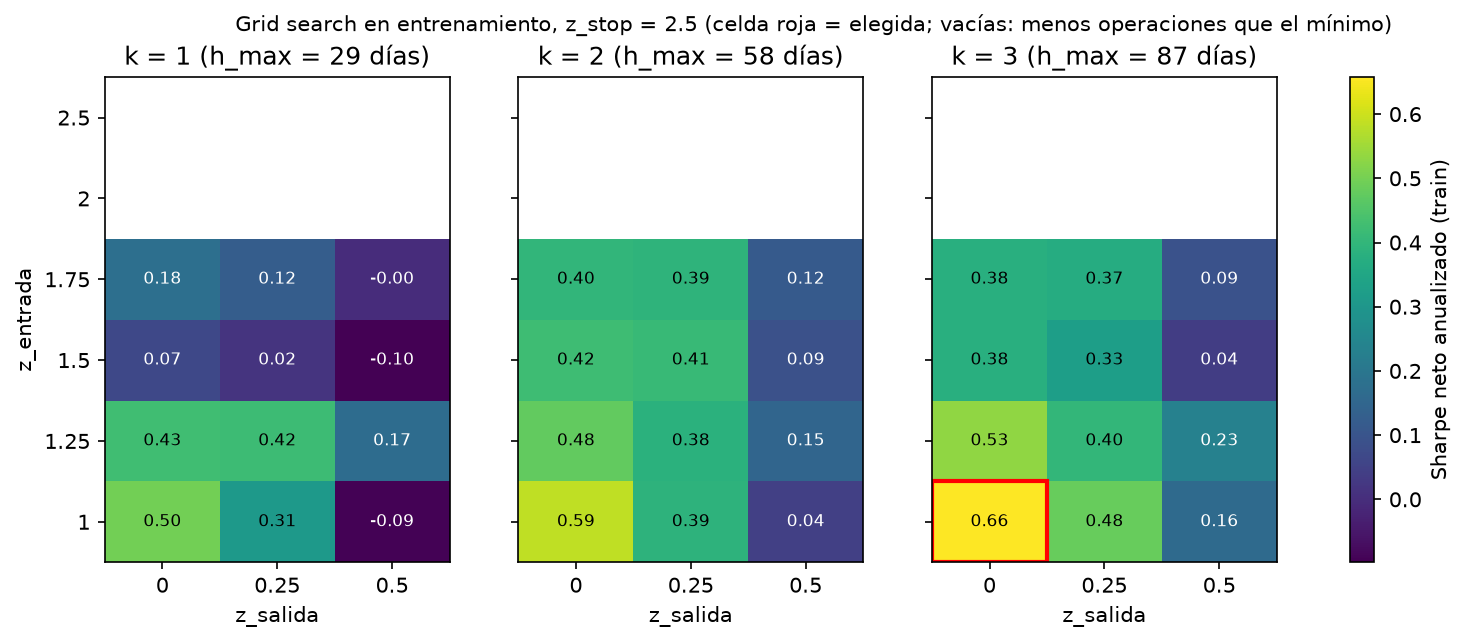

In [7]:
display(Image(FIGURES / "grid_search_heatmap.png"))

**Cómo leer el grid:**

- **El óptimo está en el borde de la rejilla:** z_entrada = 1, z_salida = 0, z_stop = 2.5 y k = 3 son los valores extremos.
  La rejilla **no se amplió** después de verlo (sería ajustar la búsqueda a los datos). Se reporta como limitación.
- **El stop sí se activa en train** (3 de 24 operaciones), así que z_stop se eligió por desempeño y no por desempate:
  con 2.5 el Sharpe es 0.66, con 3.0 baja a 0.63 y con 3.5 a 0.61.
- **Sensibilidad.** 83 % de las combinaciones válidas tiene Sharpe neto positivo en train (rango −0.26 a 0.66). El
  mejor Sharpe por umbral de entrada baja de forma ordenada: 0.66 (1.0), 0.53 (1.25), 0.45 (1.5), 0.40 (1.75).
- **Las celdas vacías** son los umbrales de entrada de 2 y 2.5, que dan menos de 10 operaciones en siete años.
- **Costos.** Con el θ elegido, las comisiones se llevan el 24 % del P&L bruto en train ($66.5 mil de $275 mil): 3
  patas, entrada, salida y rebalanceo diario. El préstamo es menor ($3.2 mil). La parte 06 compara el rebalanceo
  diario contra la banda de no-rebalanceo.

## 6. Parámetros congelados (`params.json` → `strategy`)

Se fijan aquí, con train, antes de mirar prueba y validación.

In [8]:
print(json.dumps({k: v for k, v in strategy.items() if k != "grid"}, indent=2, ensure_ascii=False))

{
  "z_entry": 1.0,
  "z_exit": 0.0,
  "z_stop": 2.5,
  "max_holding": 87,
  "holding_k": 3,
  "half_life_days": 29.112791,
  "objective": "sharpe_net: Sharpe neto anualizado en train (rf = 0, √252), rebalanceo diario, costos completos",
  "train_objective": 0.65753332,
  "train_trades": 24,
  "train_period": [
    "2013-04-08",
    "2020-11-19"
  ]
}


## 7. Figura 6 — z-score con los umbrales elegidos

Con la tercia el z se mantiene acotado fuera de muestra: la estrategia entra y sale con regularidad en las tres
particiones (con posición ≈ 38 % de los días en train y ≈ 48–49 % en prueba y validación) y no toca el stop fuera de
muestra. En la iteración 1, el z de validación pasaba meses arriba de 2 y la estrategia quedaba plana casi todo 2024.

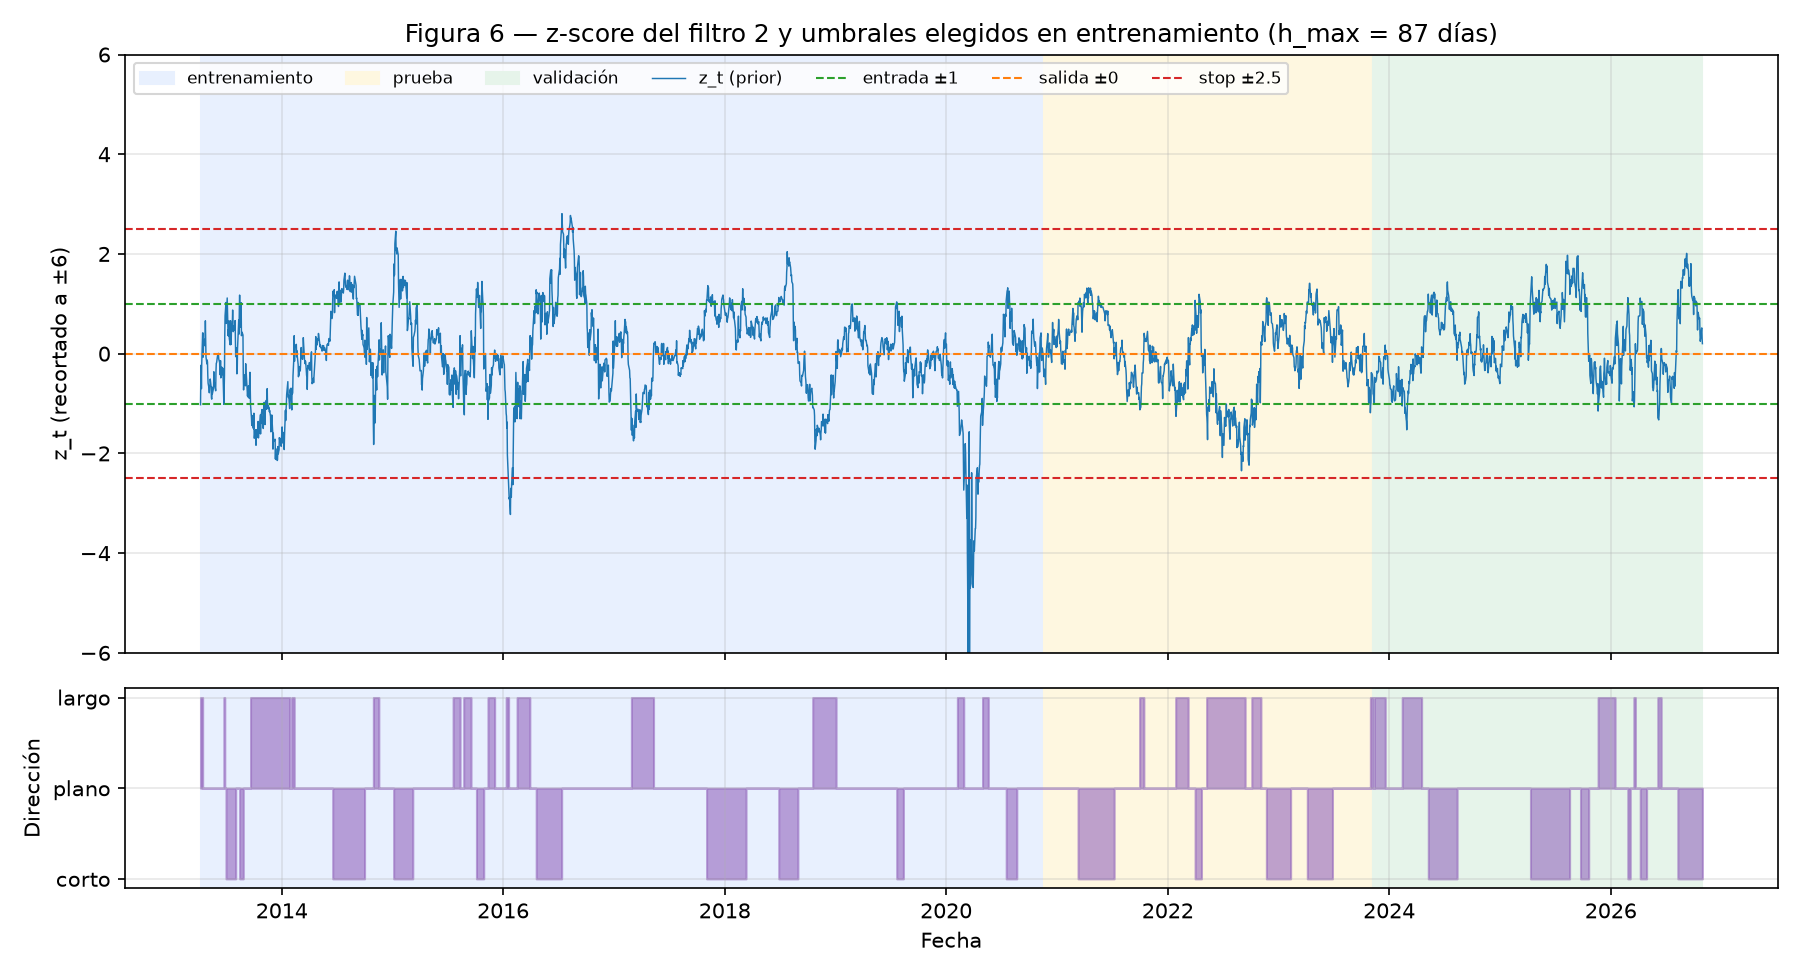

Días con posición por partición:
split
train         38%
test          48%
validation    49%
Motivos de cierre decididos por la regla:
split       exit_reason
train       salida         19
            holding         2
            stop            3
test        salida          7
            holding         1
validation  salida          9
            holding         1


In [9]:
display(Image(FIGURES / "fig06_zscore_umbrales.png"))
print("Días con posición por partición:")
print(signals.groupby("split", sort=False)["signal"].apply(lambda s: f"{(s != 0).mean():.0%}").to_string())
print("Motivos de cierre decididos por la regla:")
print(signals.loc[signals["exit_reason"] != ""].groupby(["split", "exit_reason"], sort=False).size().to_string())

## 8. Vista previa fuera de muestra con θ congelado

Cada partición arranca plana con $1,000,000 y cierra al final. Esto es solo una **vista previa** para defender la
regla; la evaluación oficial (curva de capital, bitácora y métricas) es la parte 06 (`backtest/walk_forward.py`).

In [10]:
preview = evaluate_by_split(prices, signals, rule)
display(preview[["sharpe_net", "net_return", "max_drawdown", "n_trades", "win_rate", "avg_days", "exposure",
                 "exits_salida", "exits_stop", "exits_holding", "exits_fin_particion"]])

,sharpe_net,net_return,max_drawdown,n_trades,win_rate,avg_days,exposure,exits_salida,exits_stop,exits_holding,exits_fin_particion
split,,,,,,,,,,,
train,0.6575,0.2051,-0.06547,24,0.7917,30.04,0.3751,19,3,2,0
test,0.7374,0.08072,-0.04479,9,0.8889,39.78,0.4799,7,0,1,1
validation,1.01,0.1121,-0.03723,11,0.9091,33.09,0.4879,9,0,1,1


## 9. Backtest con el ECT estático contra el dinámico (sugerencia del profesor)

A cada ECT se le calibra su propio filtro 2 en train y se le aplica **el mismo θ**. El estático dimensiona con el β̃ fijo
de Johansen y el dinámico con β̂_t del filtro 1.

In [11]:
comparison = compare_static_dynamic(prices, kf1, johansen["beta_normalized"], rule)
display(comparison[["sharpe_net", "net_return", "max_drawdown", "n_trades", "exits_stop", "kf2_half_life"]])

sharpe_net  net_return  max_drawdown  n_trades  exits_stop  kf2_half_life
ect     split                                                                                
dynamic train           0.6575      0.2051      -0.06547        24           3          22.15
        test            0.7374     0.08072      -0.04479         9           0          22.15
        validation        1.01      0.1121      -0.03723        11           0          22.15
static  train           0.7191      0.2338       -0.0706        23           3          22.79
        test            0.1988     0.01778      -0.04746         7           1          22.79
        validation       1.314      0.1661      -0.03341        13           0          22.79

**Lectura.** Con el mismo θ, el dinámico da Sharpe 0.66 / 0.74 / 1.01 y el estático 0.72 / 0.20 / 1.31 en train /
prueba / validación. El estático gana en validación pero se cae en prueba, donde su ECT deja de ser estacionario
(ADF p = 0.27); el dinámico es **más consistente** entre particiones porque absorbe la deriva de nivel de la relación
con el intercepto del filtro 1. Con pocas operaciones por partición (7 a 13), la diferencia en validación no es
concluyente; la consistencia sí es el argumento para usar el filtro 1.

## 10. Causalidad (prueba 1, `tests/test_causality.py`)

La prueba recalcula todo el pipeline con datos solo hasta t, para tres fechas posteriores al fin de train (2020-11-19):
2021-03-15, 2024-06-14 y 2026-09-15. El pipeline incluye Johansen, la calibración y corrida de ambos filtros, el VECM,
el grid search y la regla. Comprueba que la calibración, z_t y la señal en t (y en todos los días anteriores) sean
idénticos a los de la corrida completa. Además, la regla recorre z hacia adelante y el motor ejecuta en t + 1.

## Resumen de resultados (parte 05)

| Resultado | Valor |
|---|---|
| Grupo | Tercia GLD-GDX-B (iteración 2) |
| VECM (train) | r = 1, k_ar_diff = 1, constante sin restringir; β = β̃ de Johansen |
| α | GDX −0.039 (t = −4.1) y B −0.034 (t = −3.4), significativos; GLD −0.003 (t = −0.9), no significativo |
| βᵀα | −0.021 → corrige (−2 < βᵀα < 0); vida media del VECM 33.3 días (Johansen 29.1, filtro 2 22.1) |
| Interpretación | Cuando el spread se abre, **solo GDX corrige** (β̃·α = −0.039); Barrick se mueve con él y empuja en contra (+0.015); el oro casi no ajusta |
| Regla | PFA de bandas sobre z prior: stop > holding > salida direccional; rearme tras stop o holding |
| Grid (train) | 207 combinaciones, 135 con ≥ 10 operaciones; objetivo: Sharpe neto con costos y rebalanceo diario |
| θ elegido | z_entrada 1.0, z_salida 0.0, z_stop 2.5, h_max 87 días (3 vidas medias) |
| Train | Sharpe neto 0.66, rendimiento 20.5 %, 24 operaciones, 79 % ganadoras; comisiones = 24 % del P&L bruto |
| Vista previa | Sharpe neto 0.74 en prueba y 1.01 en validación (con θ congelado) |
| Estático vs dinámico | mismo θ: estático 0.20 / 1.31 en prueba / validación, dinámico 0.74 / 1.01 |
| Causalidad | pipeline truncado en 3 fechas posteriores a train → mismo z_t y misma señal |

- **Limitaciones:**
  - Los cuatro parámetros óptimos están en el borde de la rejilla, que no se amplió.
  - Diagnóstico de overfit del grid (`docs/decisiones.md`, 2026-11-07): el núcleo (entrar en |z| = 1, salir en 0) es
    robusto, pero stop y holding no son estables entre mitades de train, y el Deflated Sharpe de train es 0.82
    (N efectivo = 10): el Sharpe de train no es significativo al 95 % tras corregir por la búsqueda.
  - Fuera de muestra hay pocas operaciones (9 y 11): el Sharpe tiene mucho error de estimación.
- **Hallazgo:** con la tercia la regla sigue operando fuera de muestra sin tocar el stop; el dinámico es más
  consistente que el estático entre particiones.